In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.io import loadmat
import matplotlib.pyplot as plt

# VS Code의 실행 위치가 프로젝트 루트인지 notebooks 폴더인지 모두 대응
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
BATTERY_IDS = ["B0005", "B0006", "B0007", "B0018"]

print("실행 위치:", Path.cwd())
print("프로젝트 위치:", PROJECT_ROOT)
print("데이터 위치:", DATA_DIR)

실행 위치: c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\notebooks
프로젝트 위치: c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh
데이터 위치: c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\data\raw


In [2]:
mat_paths = {
    battery_id: DATA_DIR / f"{battery_id}.mat"
    for battery_id in BATTERY_IDS
}

for battery_id, path in mat_paths.items():
    print(battery_id, ":", path.exists(), "-", path)    

B0005 : True - c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\data\raw\B0005.mat
B0006 : True - c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\data\raw\B0006.mat
B0007 : True - c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\data\raw\B0007.mat
B0018 : True - c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\data\raw\B0018.mat


In [3]:
battery_data = {}

for battery_id, path in mat_paths.items():
    mat = loadmat(path, simplify_cells=True)

    print(f"\n[{battery_id}] MAT 최상위 key")
    print(mat.keys())

    battery_data[battery_id] = mat[battery_id]


[B0005] MAT 최상위 key
dict_keys(['__header__', '__version__', '__globals__', 'B0005'])

[B0006] MAT 최상위 key
dict_keys(['__header__', '__version__', '__globals__', 'B0006'])

[B0007] MAT 최상위 key
dict_keys(['__header__', '__version__', '__globals__', 'B0007'])

[B0018] MAT 최상위 key
dict_keys(['__header__', '__version__', '__globals__', 'B0018'])


In [4]:
for battery_id, battery in battery_data.items():
    cycles = battery["cycle"]

    cycle_types = pd.Series(
        [cycle["type"] for cycle in cycles]
    ).value_counts()

    print(f"\n[{battery_id}]")
    print("전체 기록 수:", len(cycles))
    print(cycle_types)


[B0005]
전체 기록 수: 616
impedance    278
charge       170
discharge    168
Name: count, dtype: int64

[B0006]
전체 기록 수: 616
impedance    278
charge       170
discharge    168
Name: count, dtype: int64

[B0007]
전체 기록 수: 616
impedance    278
charge       170
discharge    168
Name: count, dtype: int64

[B0018]
전체 기록 수: 319
charge       134
discharge    132
impedance     53
Name: count, dtype: int64


In [5]:
from scipy.io import loadmat

path = PROJECT_ROOT / "data" / "raw" / "B0005.mat"

mat = loadmat(path, simplify_cells=True)
cycles = mat["B0005"]["cycle"]

first_charge = next(c for c in cycles if c["type"] == "charge")
first_discharge = next(c for c in cycles if c["type"] == "discharge")

print("[Charge]")
print("cycle keys:", first_charge.keys())
print("data keys:", first_charge["data"].keys())

print("\n[Discharge]")
print("cycle keys:", first_discharge.keys())
print("data keys:", first_discharge["data"].keys())

print("\nDischarge Capacity:")
print(first_discharge["data"]["Capacity"])

[Charge]
cycle keys: dict_keys(['type', 'ambient_temperature', 'time', 'data'])
data keys: dict_keys(['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time'])

[Discharge]
cycle keys: dict_keys(['type', 'ambient_temperature', 'time', 'data'])
data keys: dict_keys(['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity'])

Discharge Capacity:
1.8564874208181574


In [6]:
import numpy as np
from scipy.io import loadmat

battery_ids = ["B0005", "B0006", "B0007", "B0018"]

capacity_data = {}
soh_data = {}

for battery_id in battery_ids:
    path = PROJECT_ROOT / "data" / "raw" / f"{battery_id}.mat"
    mat = loadmat(path, simplify_cells=True)

    cycles = mat[battery_id]["cycle"]

    capacities = np.array([
        cycle["data"]["Capacity"]
        for cycle in cycles
        if cycle["type"] == "discharge"
    ], dtype=float)

    soh = capacities / capacities[0]

    capacity_data[battery_id] = capacities
    soh_data[battery_id] = soh

    print(f"[{battery_id}]")
    print("cycles   :", len(capacities))
    print("Q1       :", capacities[0])
    print("Q_last   :", capacities[-1])
    print("SOH_last :", soh[-1])
    print("NaN      :", np.isnan(soh).sum())
    print()

[B0005]
cycles   : 168
Q1       : 1.8564874208181574
Q_last   : 1.3250793286429356
SOH_last : 0.7137561578838874
NaN      : 0

[B0006]
cycles   : 168
Q1       : 2.035337591005598
Q_last   : 1.1856752327929356
SOH_last : 0.582544752296905
NaN      : 0

[B0007]
cycles   : 168
Q1       : 1.89105229539079
Q_last   : 1.4324552720625434
SOH_last : 0.7574910940083355
NaN      : 0

[B0018]
cycles   : 132
Q1       : 1.8550045207910817
Q_last   : 1.341051440640485
SOH_last : 0.7229370201580871
NaN      : 0



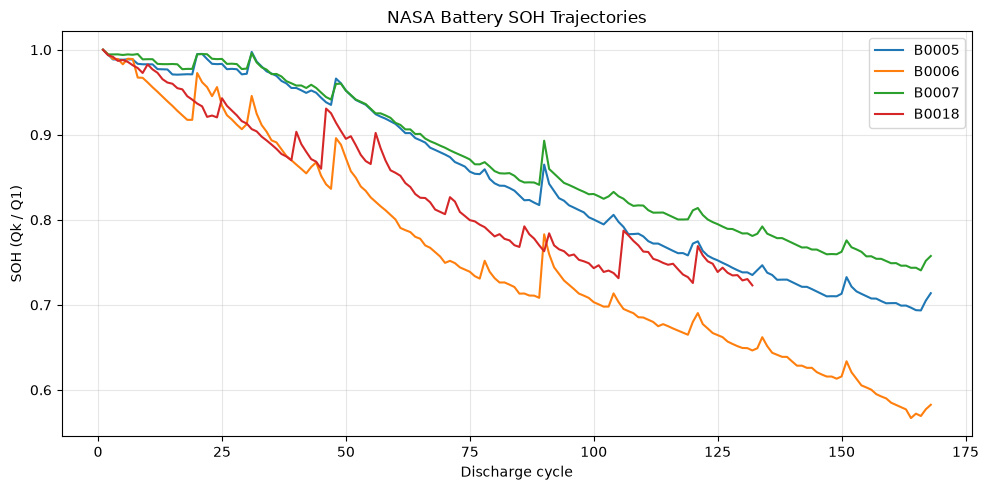

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for battery_id in battery_ids:
    soh = soh_data[battery_id]
    cycles = np.arange(1, len(soh) + 1)

    plt.plot(cycles, soh, label=battery_id)

plt.xlabel("Discharge cycle")
plt.ylabel("SOH (Qk / Q1)")
plt.title("NASA Battery SOH Trajectories")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
CONTEXT_LENGTH = 64
PREDICTION_LENGTH = 16

for battery_id, soh in soh_data.items():
    n = len(soh)
    n_windows = n - CONTEXT_LENGTH - PREDICTION_LENGTH + 1

    print(
        f"{battery_id}: "
        f"{n} cycles -> {n_windows} windows"
    )

B0005: 168 cycles -> 89 windows
B0006: 168 cycles -> 89 windows
B0007: 168 cycles -> 89 windows
B0018: 132 cycles -> 53 windows


In [18]:
def make_windows(series, context_length=64, prediction_length=16):
    X = []
    y = []

    total_length = context_length + prediction_length

    for start in range(len(series) - total_length + 1):
        context = series[start:start + context_length]
        target = series[
            start + context_length:
            start + total_length
        ]

        X.append(context)
        y.append(target)

    return np.array(X), np.array(y)

In [13]:
windows = {}

for battery_id, soh in soh_data.items():
    X, y = make_windows(
        soh,
        CONTEXT_LENGTH,
        PREDICTION_LENGTH
    )

    windows[battery_id] = {
        "X": X,
        "y": y
    }

    print(
        f"{battery_id}: "
        f"X {X.shape}, y {y.shape}"
    )

B0005: X (89, 64), y (89, 16)
B0006: X (89, 64), y (89, 16)
B0007: X (89, 64), y (89, 16)
B0018: X (53, 64), y (53, 16)


In [14]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


last_value_results = {}

for battery_id, data in windows.items():
    X = data["X"]
    y = data["y"]

    # context의 마지막 SOH를 16-step horizon 전체에 반복
    y_pred = np.repeat(
        X[:, -1][:, None],
        PREDICTION_LENGTH,
        axis=1
    )

    battery_rmse = rmse(y, y_pred)
    battery_mae = mae(y, y_pred)

    last_value_results[battery_id] = {
        "rmse": battery_rmse,
        "mae": battery_mae
    }

    print(
        f"{battery_id}: "
        f"RMSE={battery_rmse:.6f}, "
        f"MAE={battery_mae:.6f}"
    )

B0005: RMSE=0.022004, MAE=0.018166
B0006: RMSE=0.024485, MAE=0.019867
B0007: RMSE=0.017806, MAE=0.014452
B0018: RMSE=0.022700, MAE=0.018771


In [15]:
macro_rmse = np.mean([
    result["rmse"]
    for result in last_value_results.values()
])

macro_mae = np.mean([
    result["mae"]
    for result in last_value_results.values()
])

print(f"\nMacro RMSE: {macro_rmse:.6f}")
print(f"Macro MAE : {macro_mae:.6f}")


Macro RMSE: 0.021749
Macro MAE : 0.017814


In [16]:
def linear_trend_predict(X, prediction_length):
    context_length = X.shape[1]

    x_context = np.arange(context_length)
    x_future = np.arange(
        context_length,
        context_length + prediction_length
    )

    predictions = []

    for context in X:
        slope, intercept = np.polyfit(
            x_context,
            context,
            deg=1
        )

        y_pred = slope * x_future + intercept
        predictions.append(y_pred)

    return np.array(predictions)

In [17]:
linear_results = {}

for battery_id, data in windows.items():
    X = data["X"]
    y = data["y"]

    y_pred = linear_trend_predict(
        X,
        PREDICTION_LENGTH
    )

    battery_rmse = rmse(y, y_pred)
    battery_mae = mae(y, y_pred)

    linear_results[battery_id] = {
        "rmse": battery_rmse,
        "mae": battery_mae
    }

    print(
        f"{battery_id}: "
        f"RMSE={battery_rmse:.6f}, "
        f"MAE={battery_mae:.6f}"
    )

macro_rmse = np.mean([
    result["rmse"]
    for result in linear_results.values()
])

macro_mae = np.mean([
    result["mae"]
    for result in linear_results.values()
])

print(f"\nMacro RMSE: {macro_rmse:.6f}")
print(f"Macro MAE : {macro_mae:.6f}")

B0005: RMSE=0.019174, MAE=0.015175
B0006: RMSE=0.026631, MAE=0.019419
B0007: RMSE=0.016162, MAE=0.013084
B0018: RMSE=0.030008, MAE=0.022639

Macro RMSE: 0.022994
Macro MAE : 0.017579
